# 10 — Optuna tuning under low-margin payment economics

Tune LightGBM on **three grouped folds inside the training split**. The objective is pooled out-of-fold simulated profit per 1,000 payments, assuming +0.3% legitimate margin / −100% fraud loss / zero cancellation payoff. The economic cutoff remains fixed at `0.003 / 1.003`; Amount, Time, and V1–V28 remain model inputs.

The 40-trial seeded TPE search includes the current model settings as trial 0. Calibration and evaluation are excluded. The CV winner is frozen before selection is scored. Selection is a reused development comparison, not an independent final test.

This notebook reads the completed experiment. To run a **new** study, use a new name so prior results are preserved:
```bash
poetry run python -m pip install --no-deps -r requirements-tuning.txt
poetry run python -m scripts.run_optuna --trials 40 --study-name lightgbm-low-margin-optuna-v2
```

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/evaluation.json").exists())
RESULTS = ROOT / "reports/optuna/lightgbm-low-margin-optuna-v1"
report = json.loads((RESULTS / "results.json").read_text())
trials = pd.read_csv(RESULTS / "trials.csv")
pd.Series({"completed_trials": report["completed_trials"], "best_trial": report["best_trial"],
           "baseline_cv_profit_per_1000": report["baseline_cv_profit_per_1000"],
           "best_cv_profit_per_1000": report["best_cv_profit_per_1000"],
           "elapsed_seconds": report["elapsed_seconds"],
           "mlflow_parent_run_id": report["mlflow_parent_run_id"]})

Matplotlib is building the font cache; this may take a moment.


completed_trials                                             40
best_trial                                                   36
baseline_cv_profit_per_1000                          210.602613
best_cv_profit_per_1000                              231.745789
elapsed_seconds                                       112.21501
mlflow_parent_run_id           f5f9c2a5736e42ac952f8e67c8ac3c42
dtype: object

## Search behavior and the separate development comparison

CV values guided Optuna. Selection values were measured only after the winning parameters were fixed.

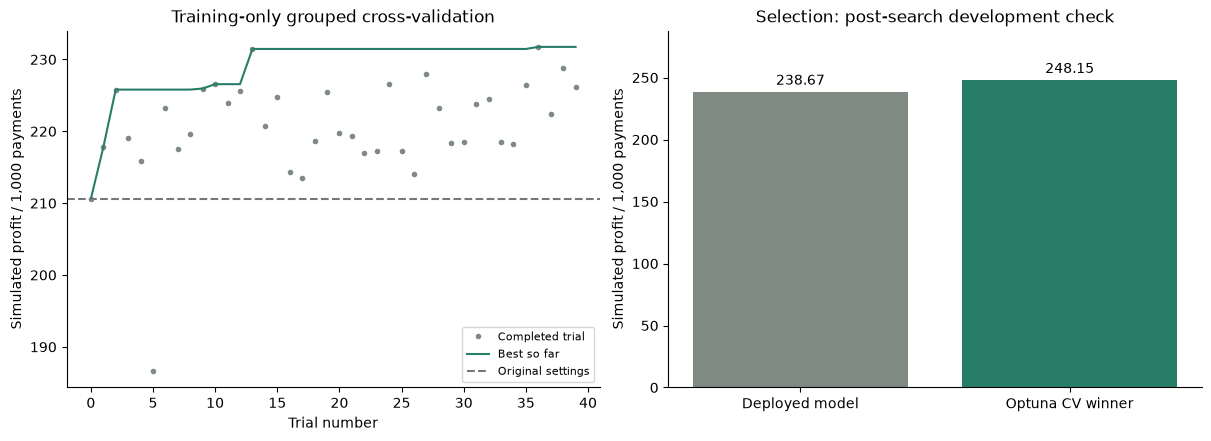

In [2]:
comparison = pd.DataFrame(report["selection_results"]).T
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), constrained_layout=True)
axes[0].plot(trials["number"], trials["value"], ".", color="#7e8a82", label="Completed trial")
axes[0].plot(trials["number"], trials["value"].cummax(), color="#287d68", label="Best so far")
axes[0].axhline(report["baseline_cv_profit_per_1000"], color="#74787d", linestyle="--", label="Original settings")
axes[0].set(title="Training-only grouped cross-validation", xlabel="Trial number", ylabel="Simulated profit / 1,000 payments")
axes[0].legend(fontsize=8)
values = comparison.loc[["deployed_lightgbm", "optuna_lightgbm"], "simulated_profit_per_1000"]
axes[1].bar(["Deployed model", "Optuna CV winner"], values, color=["#7e8a82", "#287d68"])
axes[1].set(title="Selection: post-search development check", ylabel="Simulated profit / 1,000 payments")
for index, value in enumerate(values):
    axes[1].annotate(f"{value:.2f}", (index, value), xytext=(0, 5), textcoords="offset points", ha="center")
axes[1].set_ylim(min(0, values.min() * 1.2), max(1, values.max() * 1.16))
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
(ROOT / "reports/figures").mkdir(exist_ok=True)
fig.savefig(ROOT / "reports/figures/optuna-low-margin-search.png", dpi=180)
plt.show()

In [3]:
comparison[["rows", "frauds", "average_precision", "brier_score", "simulated_profit_per_1000",
            "frauds_canceled", "legitimate_canceled", "legitimate_cancellation_rate"]]

,rows,frauds,average_precision,brier_score,simulated_profit_per_1000,frauds_canceled,legitimate_canceled,legitimate_cancellation_rate
optuna_lightgbm,42632.0,76.0,0.856445,0.000468,248.145147,65.0,371.0,0.008718
deployed_lightgbm,42632.0,76.0,0.842098,0.000432,238.668085,62.0,90.0,0.002115


## Winning parameters and uncertainty

The paired group bootstrap below conditions on the fixed fitted models and reused selection payments. It does not capture all uncertainty from the hyperparameter search or prior analysis.

In [4]:
display(pd.Series(report["best_parameters"], name="Winning parameters"))
pd.DataFrame(report["selection_uncertainty"]["paired_differences"])

n_estimators         150.000000
learning_rate          0.059132
num_leaves            13.000000
min_child_samples    145.000000
reg_alpha              0.047629
reg_lambda             4.952860
subsample              0.850741
colsample_bytree       0.717891
Name: Winning parameters, dtype: float64

,candidate,comparator,profit_difference_per_1000,lower_95,upper_95,conclusion
0,optuna_lightgbm,deployed_lightgbm,9.477062,-9.115868,36.856456,inconclusive


## Scope

The study, all trials, source/split/cost/code hashes, and final tuned artifact are logged in MLflow experiment `10-optuna-low-margin`. The SQLite study and fitted model remain local; compact trial/results files are committed.

The deployed artifact is preserved. Tuning is complete for this experiment; calibration of the tuned model and a disclosed subsequent evaluation are separate steps. This notebook makes no production-profit or independent-final-test claim.